In [65]:
%pip install statsmodels openpyxl xgboost



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [66]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [67]:
import pandas as pd

# Load the Excel file into a DataFrame
df = pd.read_excel('spu_monthly_msw.xlsx')
# Drop specific columns by passing a list
df = df.drop(['YEAR', 'MONTH'], axis=1)

df['Date'] = pd.to_datetime(df['Date'])


In [68]:
# Observe data
df.info()
print(df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36174 entries, 0 to 36173
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              36174 non-null  datetime64[ns]
 1   Transfer Station  36174 non-null  object        
 2   COMMODITY         36174 non-null  object        
 3   TONS              36174 non-null  float64       
 4   TRIPS             36174 non-null  int64         
 5   SECTOR            36174 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(3)
memory usage: 1.7+ MB
Date                0
Transfer Station    0
COMMODITY           0
TONS                0
TRIPS               0
SECTOR              0
dtype: int64
Exact duplicate rows: 0


In [69]:
monthly_record = df.pivot_table(
    index=pd.Grouper(key='Date', freq='MS'),
    columns='COMMODITY',
    aggfunc='size',
    fill_value=0
)
monthly_record

COMMODITY,Garbage,Organics,Recycling
Date,,,
2009-03-01,7,6,3
2009-04-01,93,77,32
2009-05-01,95,77,45
2009-06-01,94,75,38
2009-07-01,96,80,33
...,...,...,...
2026-05-01,60,79,35
2026-06-01,59,81,31
2026-07-01,60,82,32


Looking at this table, it seems March 2006 and September 2026 have unusual low count compared to other months, checking if they are solely imcomplete reporting, or they suggest predictive signals

In [70]:
df['Date'] = pd.to_datetime(df['Date'])

coverage = df.groupby(df['Date'].dt.to_period('M')).agg(
    first_record=('Date', 'min'),
    last_record=('Date', 'max'),
    records=('Date', 'size'),
    days_with_records=('Date', 'nunique')
)
coverage

,first_record,last_record,records,days_with_records
Date,,,,
2009-03,2009-03-30,2009-03-31,16,2
2009-04,2009-04-01,2009-04-30,202,30
2009-05,2009-05-01,2009-05-31,217,31
2009-06,2009-06-01,2009-06-30,207,30
2009-07,2009-07-01,2009-07-31,209,31
...,...,...,...,...
2026-05,2026-05-01,2026-05-31,174,31
2026-06,2026-06-01,2026-06-30,171,30
2026-07,2026-07-01,2026-07-31,174,31


Indeed, data from 03/2009 and 09/2026 doesn't cover a full month tonnage. So I will exclude these months from the training data.

In [71]:
monthly_weight = df.pivot_table(
    index=pd.Grouper(key='Date', freq='ME'),
    columns='COMMODITY',
    values='TONS',       
    aggfunc='sum',
    fill_value=0
)
# Drop 03/2009 due to insufficient data
monthly_weight = monthly_weight.drop(['2009-03-31', '2026-09-30'])
monthly_weight['total_msw'] = (
    monthly_weight['Garbage']
    + monthly_weight['Organics']
    + monthly_weight['Recycling']
)

monthly_weight['recovery_rate'] = (
    (monthly_weight['Recycling'] + monthly_weight['Organics'])
    / monthly_weight['total_msw']
)
monthly_weight

COMMODITY,Garbage,Organics,Recycling,total_msw,recovery_rate
Date,,,,,
2009-04-30,9094.146759,8367.236934,6237.569050,23698.952743,0.616264
2009-05-31,8455.658332,9565.702195,6047.685488,24069.046015,0.648692
2009-06-30,8786.974507,8799.011525,6551.834938,24137.820970,0.635967
2009-07-31,9101.051299,6388.114913,6945.981692,22435.147904,0.594340
2009-08-31,8781.411878,5322.974296,6250.595241,20354.981415,0.568587
...,...,...,...,...,...
2026-04-30,10914.939734,7568.014130,5948.768485,24431.722349,0.553247
2026-05-31,10791.888987,7895.505435,5669.710872,24357.105294,0.556931
2026-06-30,11526.716169,7536.879671,6241.322520,25304.918360,0.544487


In [72]:
# Calculate the number of months reported each year

monthly_msw_counts = monthly_weight.groupby(
    monthly_weight.index.year
)[['Garbage', 'Organics', 'Recycling']].count()

monthly_msw_counts

COMMODITY,Garbage,Organics,Recycling
Date,,,
2009,9,9,9
2010,12,12,12
2011,12,12,12
2012,12,12,12
2013,12,12,12
2014,12,12,12
2015,12,12,12
2016,12,12,12
2017,12,12,12


### Exogenous Variable

#### Temperature DF
https://www.ncei.noaa.gov/access/monitoring/climate-at-a-glance/city/time-series/USW00024233/tavg/1/0/2009-2026
cite this


In [73]:
import pandas as pd

# Load the Excel file into a DataFrame
temp_df = pd.read_csv('monthly_avg_temp.csv')
temp_df = temp_df.iloc[2:].copy() # skip the first 2 header rows
temp_df.columns = ['Date', 'avg_temp']

temp_df['Date'] = (
    pd.to_datetime(temp_df['Date'].astype(str), format='%Y%m') 
      .dt.to_period('M')
      .dt.to_timestamp('M') # convert tseries to EOM datetime to match waste DF
)
temp_df['avg_temp'] = pd.to_numeric(temp_df['avg_temp'])

temp_df = temp_df.set_index('Date').sort_index()
# Include months that align with waste DF
temp_df = temp_df.iloc[3:-1]
temp_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 209 entries, 2009-04-30 to 2026-08-31
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   avg_temp  209 non-null    float64
dtypes: float64(1)
memory usage: 3.3 KB


#### Precipitation DF

In [74]:
import pandas as pd

# Load the Excel file into a DataFrame
rain_df = pd.read_csv('monthly_precipitation.csv')
rain_df = rain_df.iloc[2:].copy()
rain_df.columns = ['Date', 'tot_rain']

rain_df['Date'] = (
    pd.to_datetime(rain_df['Date'].astype(str), format='%Y%m')
      .dt.to_period('M')
      .dt.to_timestamp('M')
)
rain_df['tot_rain'] = pd.to_numeric(rain_df['tot_rain'])

rain_df = rain_df.set_index('Date').sort_index()
rain_df = rain_df.iloc[3:-1] #collect from 04/2009-08/2026 to match waste DF
rain_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 209 entries, 2009-04-30 to 2026-08-31
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   tot_rain  209 non-null    float64
dtypes: float64(1)
memory usage: 3.3 KB


#### Number of Households

In [75]:
exo_df = pd.read_csv('Housing Units by Year Table.csv')
exo_df = exo_df[['Year_Display','SUM_HOUSING_UNITS']]
exo_df = exo_df.rename(columns={"Year_Display":"Date", "SUM_HOUSING_UNITS": "Households"})

exo_df = exo_df.set_index('Date')

# Create monthly date range (04/2009-08/2026)
monthly_dates = pd.date_range(
    start='2009-04-30',
    end='2026-08-31',
    freq='ME'
)

# Expand annual data to monthly frequency
exo_monthly = exo_df.reindex(monthly_dates.year)

# Assign monthly dates as DAtetimeIndex
exo_monthly.index = monthly_dates


exo_monthly.info()


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 209 entries, 2009-04-30 to 2026-08-31
Freq: ME
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Households  209 non-null    int64
dtypes: int64(1)
memory usage: 3.3 KB


In [76]:
# Check fr matching index
print(monthly_weight.index)
print(temp_df.index)
print(rain_df.index)
print(exo_monthly.index)

DatetimeIndex(['2009-04-30', '2009-05-31', '2009-06-30', '2009-07-31',
               '2009-08-31', '2009-09-30', '2009-10-31', '2009-11-30',
               '2009-12-31', '2010-01-31',
               ...
               '2025-11-30', '2025-12-31', '2026-01-31', '2026-02-28',
               '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30',
               '2026-07-31', '2026-08-31'],
              dtype='datetime64[ns]', name='Date', length=209, freq=None)
DatetimeIndex(['2009-04-30', '2009-05-31', '2009-06-30', '2009-07-31',
               '2009-08-31', '2009-09-30', '2009-10-31', '2009-11-30',
               '2009-12-31', '2010-01-31',
               ...
               '2025-11-30', '2025-12-31', '2026-01-31', '2026-02-28',
               '2026-03-31', '2026-04-30', '2026-05-31', '2026-06-30',
               '2026-07-31', '2026-08-31'],
              dtype='datetime64[ns]', name='Date', length=209, freq=None)
DatetimeIndex(['2009-04-30', '2009-05-31', '2009-06-30', '2009-07-31',
 

In [77]:
waste_df = (
    monthly_weight
    .merge(temp_df, left_index=True, right_index=True, how='left')
    .merge(rain_df, left_index=True, right_index=True, how='left')
    .merge(exo_monthly, left_index=True, right_index=True, how='left')
)

waste_df.head()

,Garbage,Organics,Recycling,total_msw,recovery_rate,avg_temp,tot_rain,Households
Date,,,,,,,,
2009-04-30,9094.146759,8367.236934,6237.569050,23698.952743,0.616264,48.8,3.37,301899
2009-05-31,8455.658332,9565.702195,6047.685488,24069.046015,0.648692,55.9,3.61,301899
2009-06-30,8786.974507,8799.011525,6551.834938,24137.820970,0.635967,63.4,0.19,301899
2009-07-31,9101.051299,6388.114913,6945.981692,22435.147904,0.594340,69.1,0.06,301899
2009-08-31,8781.411878,5322.974296,6250.595241,20354.981415,0.568587,65.2,1.16,301899


### EDA

#### Basic Overview

In [78]:
# Dataset overview
print(waste_df.info())

# Descriptive statistics
print(waste_df.describe())


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 209 entries, 2009-04-30 to 2026-08-31
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Garbage        209 non-null    float64
 1   Organics       209 non-null    float64
 2   Recycling      209 non-null    float64
 3   total_msw      209 non-null    float64
 4   recovery_rate  209 non-null    float64
 5   avg_temp       209 non-null    float64
 6   tot_rain       209 non-null    float64
 7   Households     209 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 14.7 KB
None
            Garbage      Organics    Recycling     total_msw  recovery_rate  \
count    209.000000    209.000000   209.000000    209.000000     209.000000   
mean    9634.755200   7133.670968  6886.601621  23655.027789       0.590436   
std      934.606739   1870.363808   649.755333   2408.749625       0.040535   
min     7722.941453   3153.872512  5347.423378  17592.418491     

#### With smoothing avg

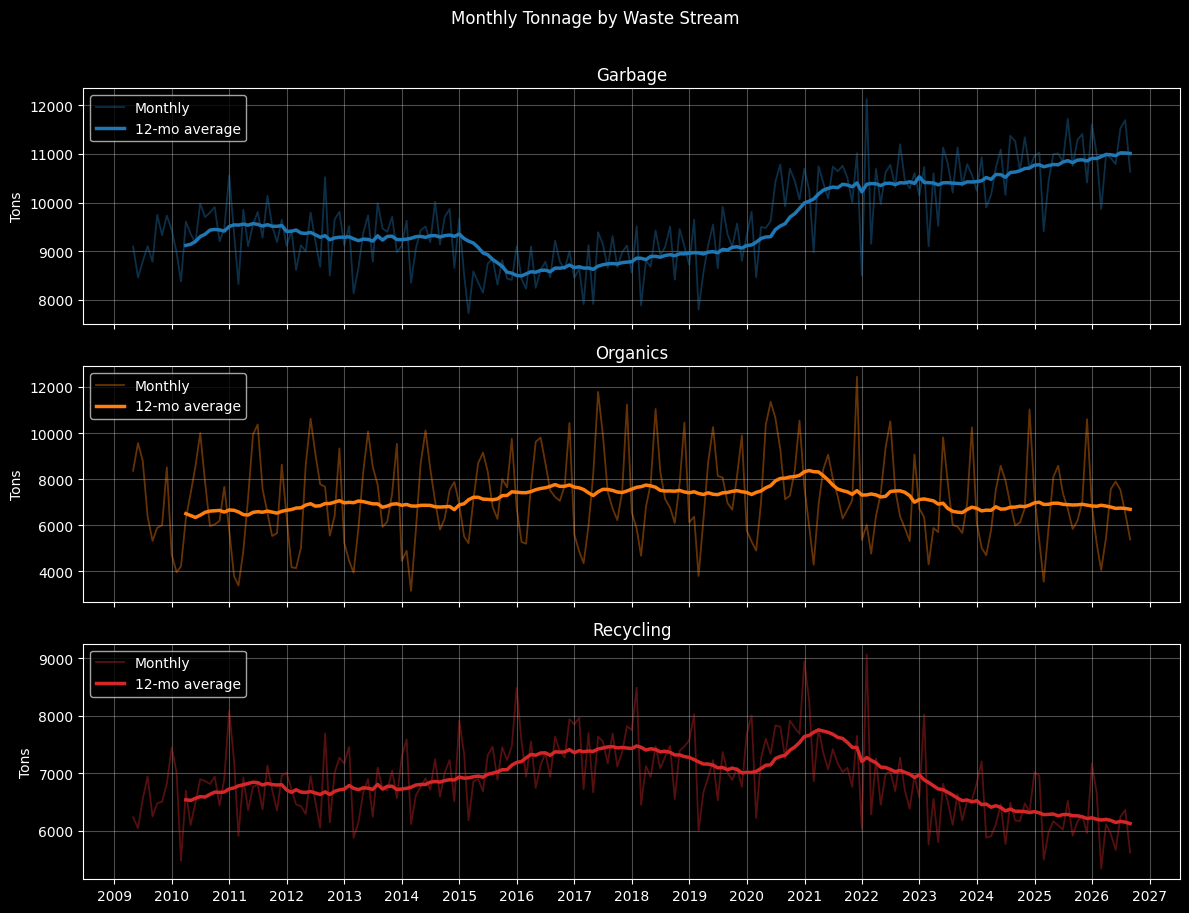

In [79]:
import matplotlib.dates as mdates
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {'Garbage': 'tab:blue', 'Organics': 'tab:orange', 'Recycling': 'tab:red'}

for ax, stream in zip(axes, colors):
    ax.plot(waste_df[stream], color=colors[stream], alpha=0.4, linewidth=1.3, label='Monthly')
    ax.plot(waste_df[stream].rolling(12).mean(), color=colors[stream], linewidth=2.5, label='12-mo average')
    # tick and label every year
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.set_title(stream)
    ax.set_ylabel('Tons')
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left')

plt.suptitle('Monthly Tonnage by Waste Stream', y=1.01)
plt.tight_layout()
plt.show()

Garbage is the cleanest series. It sits around 9,000 tons through the 2010s, then steps up to roughly 10,500-11,000 from about 2019-2020 onward. That looks like a level shift, which matters for SARIMAX (differencing handles it) and XGBoost (a trend feature helps).
Organics is extremely noisy. It swings between about 3,000 and 12,000 tons month to month, with no obvious trend at this scale. That volatility will make it the hardest stream to forecast.
Recycling hovers around 6,000-8,000 tons and looks flat to slightly declining after 2022.
Organics and Recycling overlap heavily.

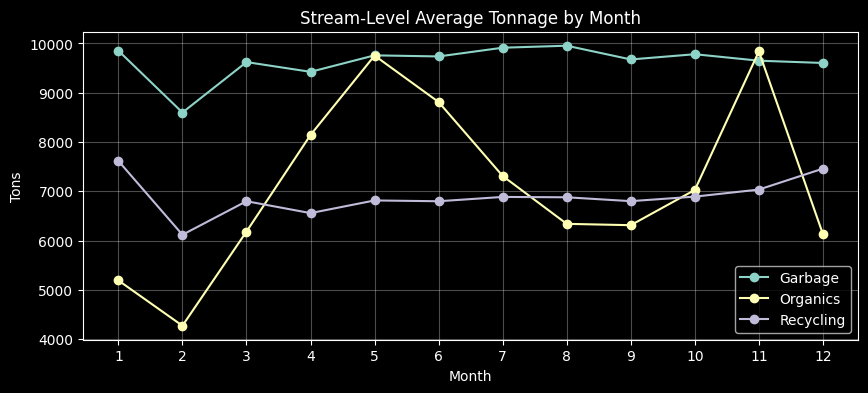

In [80]:
# Seasonality: average tonnage by calendar month
streams = ['Garbage', 'Organics', 'Recycling']
seasonal = waste_df[streams].groupby(waste_df.index.month).mean()
seasonal.plot(marker='o', figsize=(10, 4))
plt.title('Stream-Level Average Tonnage by Month')
plt.xlabel('Month')
plt.ylabel('Tons')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

- Organics has strong, real seasonality. It troughs in February (~4,300 tons), climbs to a spring peak in May (~9,800), dips through the summer to ~6,300 in August and September, then spikes again in November (~9,800). That two-peak shape is typical of yard waste: spring growth and fall leaf cleanup. So the huge month-to-month swings in the first plot weren’t noise. Much of it is predictable seasonal signal, which is good news for forecasting Organics.
- January is higher in Recycling and slightly in Garbage. That would fit post-holiday volume (packaging, trees if they’re counted under organics or garbage).

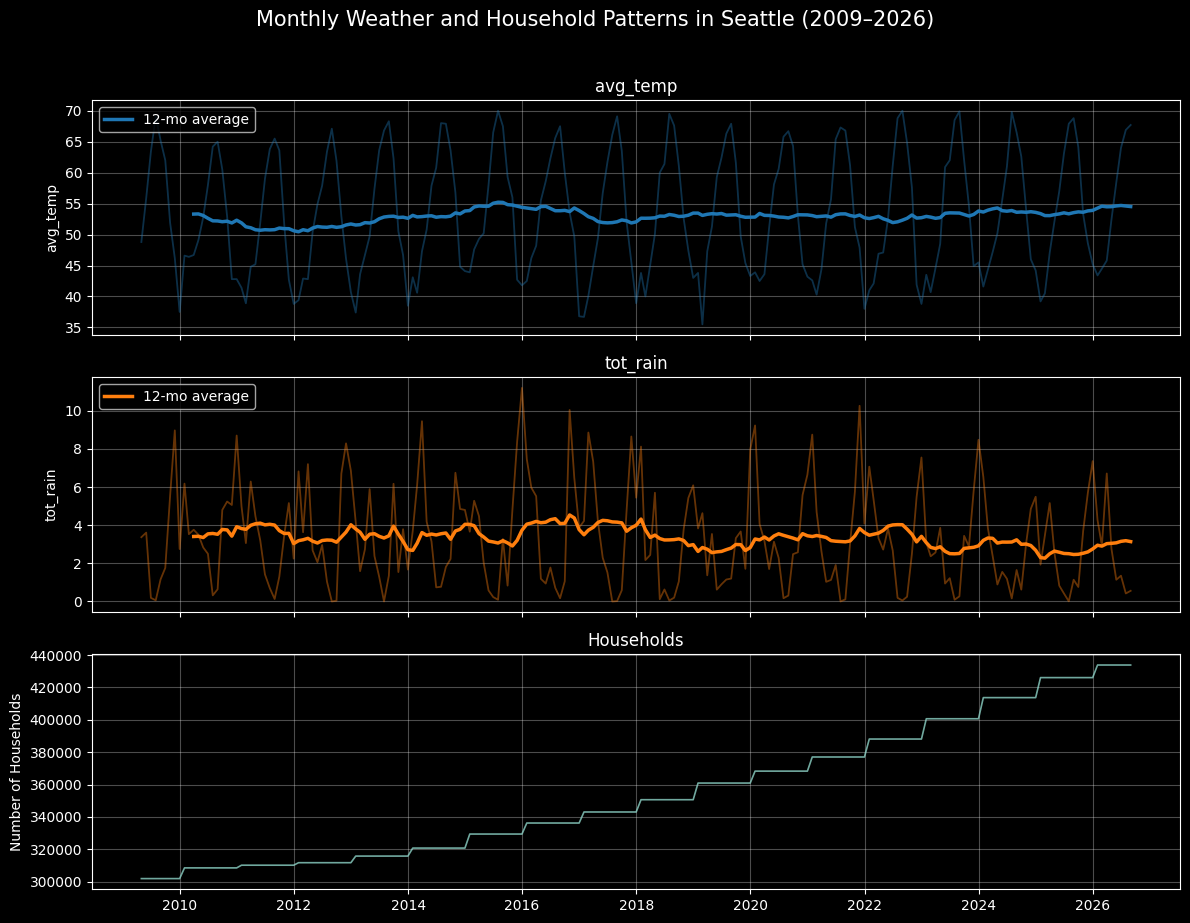

In [81]:
# Observe weather trends
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {'avg_temp': 'tab:blue', 'tot_rain': 'tab:orange'}
labels = {'avg_temp': 'Avg temperature (°F)', 'tot_rain': 'Total rainfall (in)'}

for ax, weather, unit in zip(axes[:2], colors, labels):
    ax.plot(waste_df[weather], color=colors[weather], alpha=0.4, linewidth=1.3,)
    ax.plot(waste_df[weather].rolling(12).mean(), color=colors[weather], linewidth=2.5, label='12-mo average')
    ax.set_title(weather)
    ax.set_ylabel(unit)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left')

axes[2].plot(waste_df['Households'], alpha=0.8, linewidth=1.2)
axes[2].set_title('Households')
axes[2].set_ylabel('Number of Households')
axes[2].grid(alpha=0.3)

plt.suptitle('Monthly Weather and Household Patterns in Seattle (2009–2026)',
             fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

#### Seasonal Decomposition

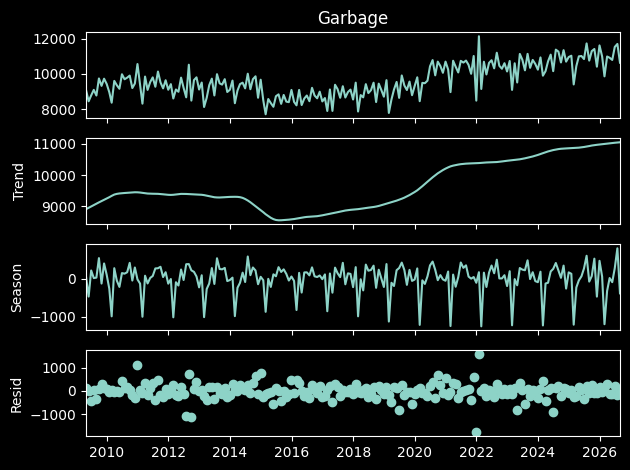

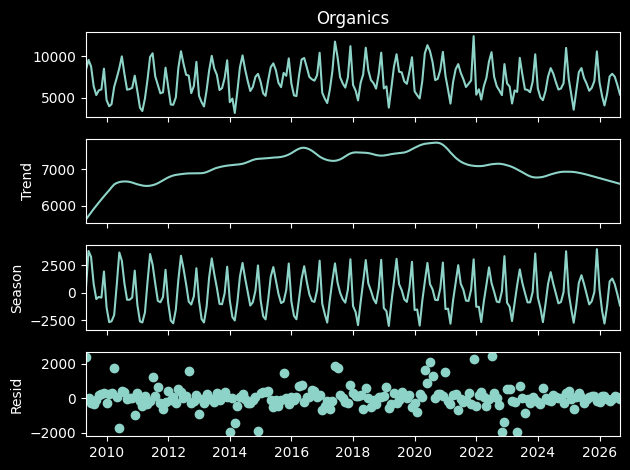

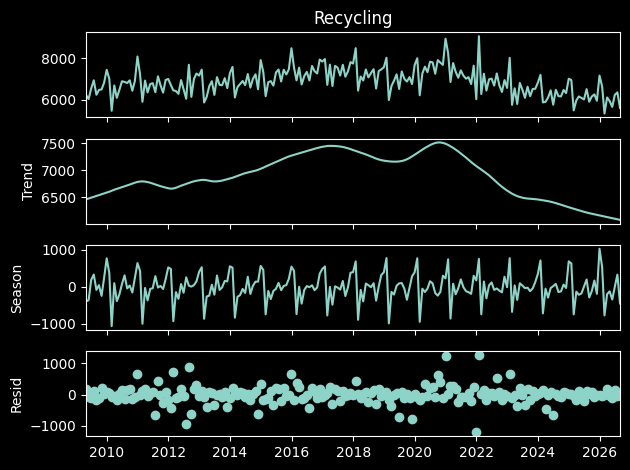

In [82]:
from statsmodels.tsa.seasonal import STL
for stream in ['Garbage', 'Organics', 'Recycling']:
    stl = STL(
    monthly_weight[stream],
    period=12,
    robust=True
    )
    result = stl.fit()
    result.plot()
    plt.show()

Strong seasonality is the dominant feature of the series.
The long-term trend increased from 2009 to around 2020, then declined gradually afterward.
Seasonal effects have an amplitude of roughly ±3,000 units.
Residuals are mostly centered around zero, indicating the decomposition explains much of the variation.
A few notable positive and negative outliers remain, particularly around 2021–2023.

This decomposition suggests that any forecasting model for the Organics series should explicitly account for the strong recurring seasonal pattern in addition to the shifting long-term trend.

#### COVID IMPACT

In [83]:
pre_covid = monthly_weight.loc[:'2020-02']
covid = monthly_weight.loc['2020-03':'2021-12']
post_covid = monthly_weight.loc['2022-01':]

for stream in [ 'Garbage', 'Organics','Recycling']:
    print('---------------------------')
    summary = pd.DataFrame({
        'Mean': [
            pre_covid[stream].mean(),
            covid[stream].mean(),
            post_covid[stream].mean()
            ],
        'Std': [
            pre_covid[stream].std(),
            covid[stream].std(),
            post_covid[stream].std()
            ]
            }, index=['Pre-COVID', 'COVID', 'Post-COVID'])
    print(f"Summary for {stream}")
    print(summary.round(2))
    print('---------------------------')

---------------------------
Summary for Garbage
                Mean     Std
Pre-COVID    9086.18  569.99
COVID       10194.00  645.99
Post-COVID  10698.32  618.49
---------------------------
---------------------------
Summary for Organics
               Mean      Std
Pre-COVID   7114.86  1887.23
COVID       8062.81  2044.95
Post-COVID  6812.67  1662.41
---------------------------
---------------------------
Summary for Recycling
               Mean     Std
Pre-COVID   6982.64  555.95
COVID       7449.70  582.12
Post-COVID  6440.73  620.87
---------------------------


In [84]:
# Heat map for exogenous vars on each stream

### ADF for 3 streams

              Series  ADF stat  p-value  Lags used  5% crit  Stationary (5%)
     Garbage (level)    -0.525   0.8871         14   -2.880            False
       Garbage (d=1)    -3.089   0.0274         14   -2.880             True
  Garbage (d=1, D=1)    -5.808   0.0000         13   -2.881             True
    Organics (level)    -2.141   0.2283         12   -2.879            False
      Organics (d=1)    -7.899   0.0000         11   -2.879             True
 Organics (d=1, D=1)    -5.457   0.0000         13   -2.881             True
   Recycling (level)    -2.029   0.2739         14   -2.880            False
     Recycling (d=1)    -2.727   0.0694         14   -2.880            False
Recycling (d=1, D=1)    -5.782   0.0000         13   -2.881             True


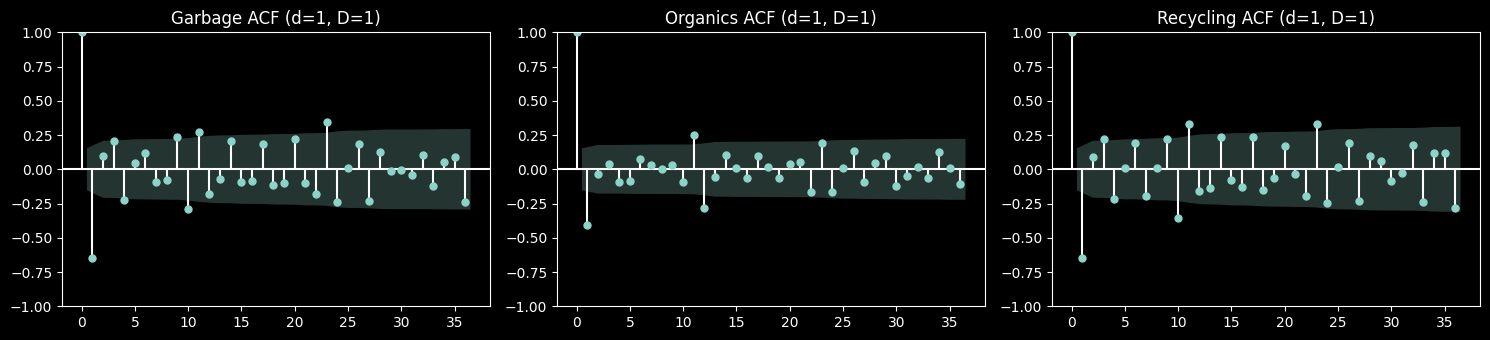

In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller


exog_cols = ['avg_temp', 'tot_rain', 'Households']
feats = exog_cols + ['covid']
TRAIN_END = '2023-12-01'
streams = ['Garbage', 'Organics', 'Recycling']

def adf_row(series, label):
    s = series.dropna()
    stat, p, lags, nobs, crit, _ = adfuller(s, autolag='AIC')
    return {'Series': label, 'ADF stat': round(stat, 3), 'p-value': round(p, 4),
            'Lags used': lags, '5% crit': round(crit['5%'], 3),
            'Stationary (5%)': p < 0.05}

rows = []
for s in streams:
    y = monthly_weight.loc[:TRAIN_END, s]
    rows.append(adf_row(y, f'{s} (level)'))
    rows.append(adf_row(y.diff(), f'{s} (d=1)'))
    rows.append(adf_row(y.diff().diff(12), f'{s} (d=1, D=1)'))

print(pd.DataFrame(rows).to_string(index=False))

# ACF of the differenced series, to support the seasonal and non-seasonal orders
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, s in zip(axes, streams):
    y = monthly_weight.loc[:TRAIN_END, s].diff().diff(12).dropna()
    plot_acf(y, lags=36, ax=ax, title=f'{s} ACF (d=1, D=1)')
plt.tight_layout()
plt.show()

#### ADF & PADF for 3 streams

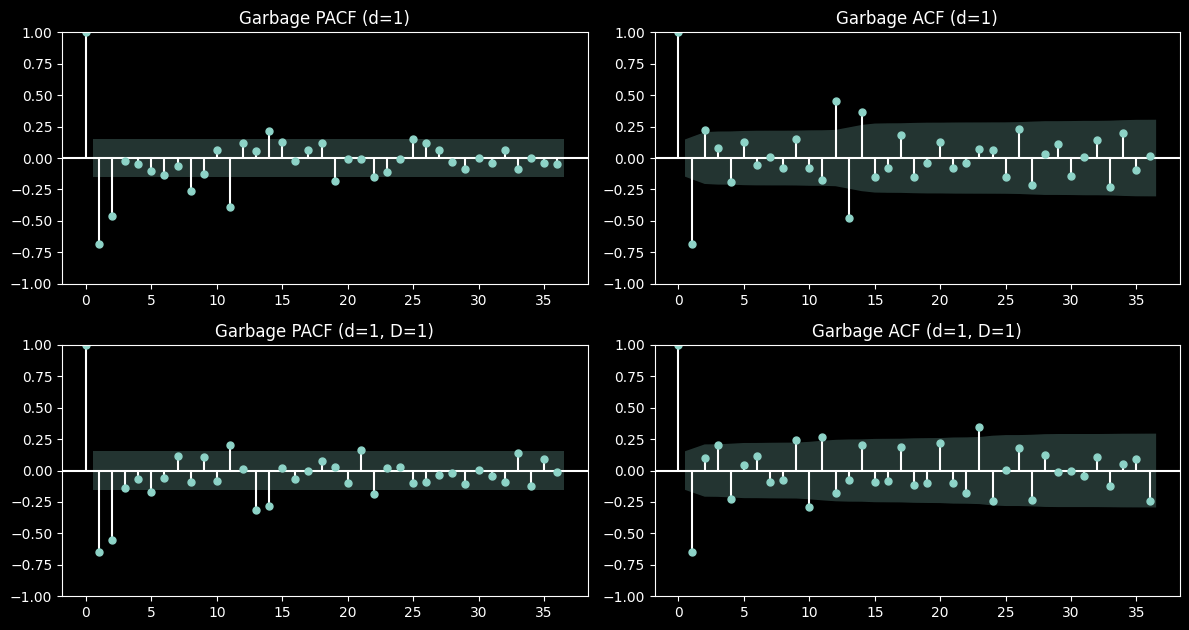

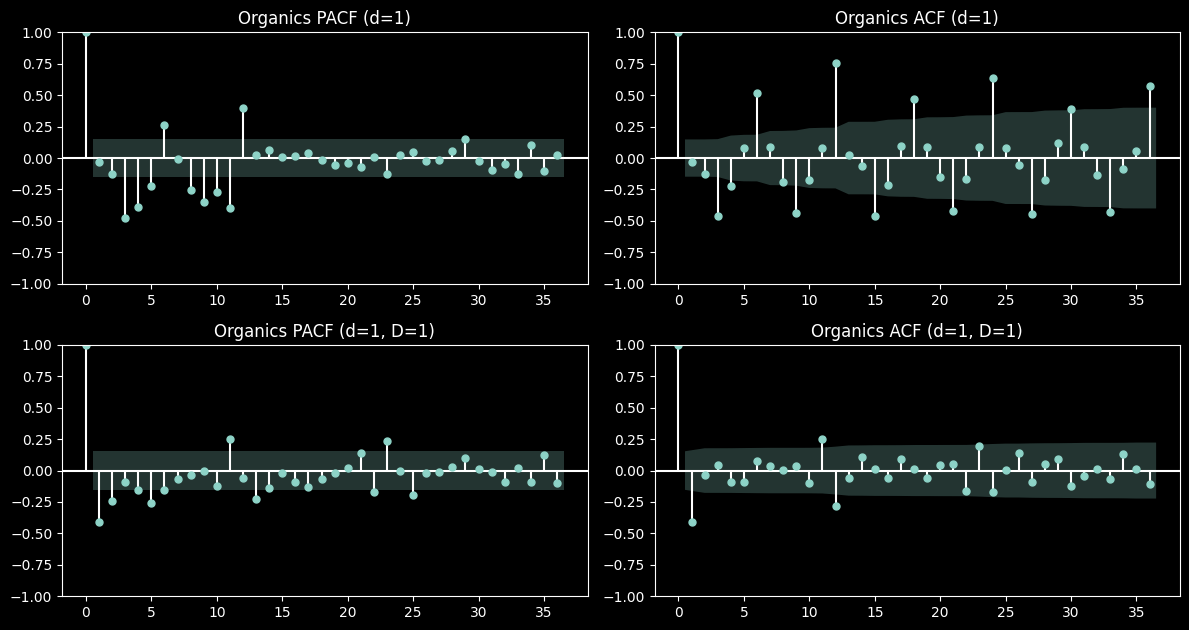

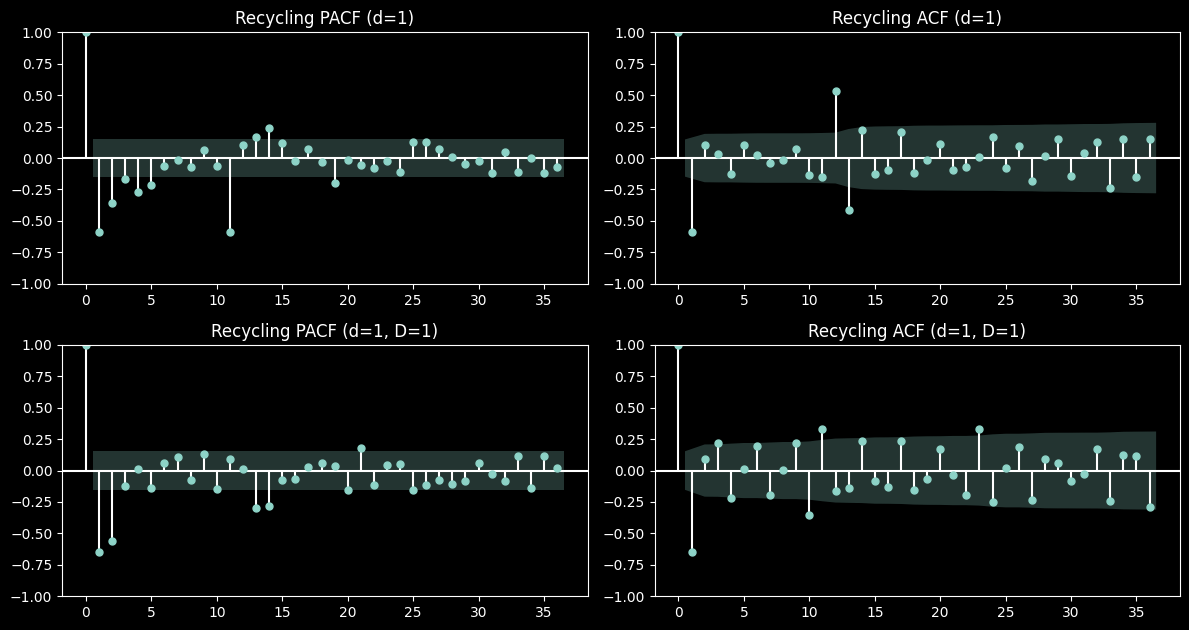

In [86]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

stages = {
    'd=1': lambda y: y.diff(),
    'd=1, D=1': lambda y: y.diff().diff(12),
}

for s in streams:
    y = monthly_weight.loc[:TRAIN_END, s]
    fig, axes = plt.subplots(len(stages), 2, figsize=(12, 3.2 * len(stages)))
    for r, (name, f) in enumerate(stages.items()):
        z = f(y).dropna()
        plot_pacf(z, lags=36, ax=axes[r, 0], title=f'{s} PACF ({name})', method='ywm')
        plot_acf(z, lags=36, ax=axes[r, 1], title=f'{s} ACF ({name})')
        
    plt.tight_layout()
    plt.show()

ADF tests on the training period failed to reject a unit root for all three level series (p > 0.22), supporting first-order differencing (d=1). ACF plots of the first-differenced series showed persistent autocorrelation at seasonal lags 12, 24, and 36, motivating seasonal differencing (D=1) for all streams. After both differences, ADF rejected the unit root for every stream (p < 0.001).
seasonal evidence was weaker than the lag-1 evidence, so the P, Q from the plots are served as candidates to the AIC
ACF/PACF inspection narrowed the candidate orders; the final orders were chosen by AIC on the training period.

 d=1, D=1, q=1, p,P,Q (P and Q at most 1, p up to 2) will use AIC on each stream training period



In [87]:
print(feats)                    # what the model was fitted with
print(exog_cols)                # what gets scaled and printed
print(sar.params.index.tolist())  # every parameter the model estimated

['avg_temp', 'tot_rain', 'Households', 'covid']
['avg_temp', 'tot_rain', 'Households']
['avg_temp', 'tot_rain', 'Households', 'covid', 'ar.L1', 'ar.L2', 'ma.L1', 'ar.S.L12', 'ma.S.L12', 'sigma2']


The plot shows SARIMAX coefficients of the scaled exogenous variables for each stream. Households had the largest coefficient in all three streams, followed by average temperature and then total rainfall. All coefficients were positive, and Organics had the largest coefficient for each variable (temperature: 760.81; rainfall: 110.06; households: 2,923.78).

#### Scale variables with StandardScaler and find SARIMA model order (p,d,q),(P,D,Q,S)

In [88]:
import itertools, warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import StandardScaler

TRAIN_END = '2023-12-31'
streams = ['Garbage', 'Organics', 'Recycling']

# mark Covid time frame
def prep(stream, source_df):
    """Select stream + exog, drop NaNs, add COVID flag."""
    df = source_df[[stream] + exog_cols].dropna().copy()
    df['covid'] = ((df.index >= '2020-03-01') & (df.index <= '2021-06-01')).astype(int)
    return df.asfreq('ME')

# use AIC to choose the best model orders (p,d,q),(P,D,Q,S)
def select_orders(stream, df, feats):
    train = df[:TRAIN_END]
    sc = StandardScaler()
    train_s = train.copy()
    train_s[exog_cols] = sc.fit_transform(train[exog_cols])
    y = train_s[stream]; X = train_s[feats]
    best = None
    for p, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1]):
        order, seas = (p, 1, 1), (P, 1, Q, 12)      # q,d,D=1 fixed from ACF (p,d,q), (P,D,Q,12)
        try:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore')
                r = SARIMAX(y, exog=X, order=order, seasonal_order=seas).fit(disp=False)
            if best is None or r.aic < best[0]:
                best = (r.aic, r.bic, order, seas)
        except Exception as e:
            print(f'  fit failed {order}{seas}: {e}')   # don't fail silently
    return best

orders = {}
for s in streams:
    df_s = prep(s, waste_df)          
    orders[s] = select_orders(s, df_s, feats)
    print(s, orders[s])

Garbage (np.float64(2481.9308914281796), np.float64(2512.9295557064215), (2, 1, 1), (1, 1, 1, 12))
Organics (np.float64(2691.0155022993604), np.float64(2715.814433721954), (1, 1, 1), (0, 1, 1, 12))
Recycling (np.float64(2407.3381002017204), np.float64(2438.3367644799623), (2, 1, 1), (1, 1, 1, 12))


In [89]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
orders = {
'Garbage':   ((2, 1, 1), (1, 1, 1, 12)),
'Organics':  ((1, 1, 1), (0, 1, 1, 12)), 
'Recycling': ((2, 1, 1), (1, 1, 1, 12)),   # filled from AIC search
     }
for s in streams:
     df = prep(s, waste_df)
     train = df[:TRAIN_END]
     sc = StandardScaler()
     train_s = train.copy()
     train_s[exog_cols] = sc.fit_transform(train[exog_cols])
     order, seasonal = orders[s]
     sar = SARIMAX(train_s[s], exog=train_s[feats],
              order=order, seasonal_order=seasonal).fit(disp=False)

     # Exogenous regressor coefficients only (excludes trend, AR, MA, seasonal, and sigma2)
     print(f'Coefficients of Exog Variables for {s}')
     exog_coefs = pd.DataFrame({"coef": sar.params[exog_cols]}) # parameter coefficients
     print(exog_coefs)

Coefficients of Exog Variables for Garbage
                  coef
avg_temp    442.927728
tot_rain     99.080859
Households  726.678424
Coefficients of Exog Variables for Organics
                   coef
avg_temp     760.813626
tot_rain     110.057562
Households  2923.775130
Coefficients of Exog Variables for Recycling
                   coef
avg_temp     364.434285
tot_rain      82.969441
Households  2308.690601


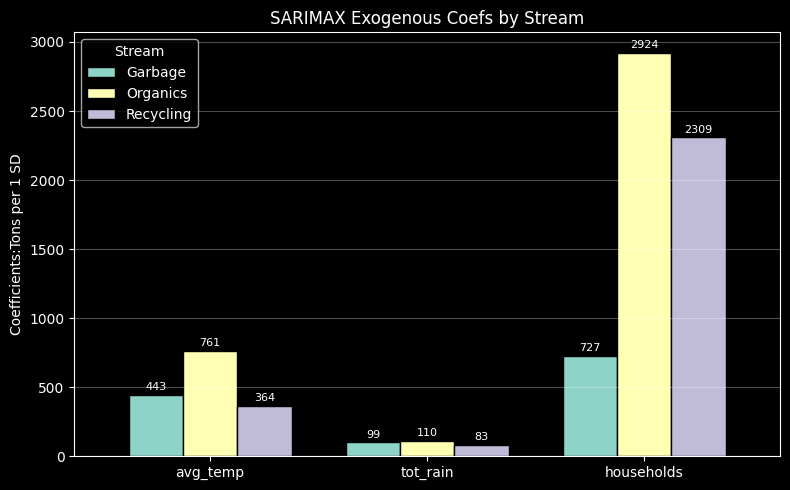

In [90]:
coefs = pd.DataFrame({
    'Garbage': [442.928, 99.08, 726.678],
    'Organics': [760.814, 110.058, 2923.775],
    'Recycling': [364.434, 82.969, 2308.691],
}, index=["avg_temp", "tot_rain", "households"])

ax = coefs.plot(kind='bar',figsize=(8,5), width=0.75, edgecolor = "black")
ax.set_ylabel("Coefficients:Tons per 1 SD")
ax.set_xlabel("")
ax.set_title("SARIMAX Exogenous Coefs by Stream")
ax.set_xticklabels(coefs.index, rotation=0)
ax.legend(title="Stream")
ax.grid(axis='y', alpha=0.3)

# values labels on bars
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f', padding=2, fontsize=8)

plt.tight_layout()
plt.show()

#### XGBOOST hyperparameter configuration

In [91]:

from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.01, 0.05, 0.1], # smaller rate slower learning, works with n_estimators
    'max_depth': [2, 3, 5], #165 observations, 2-5 branching is good
    'subsample':[0.5, 0.8, 1.0] # small subsamples could underfit, start from 50%
                }

def feat_eng(stream, source_df):
    df = prep(stream, source_df)
    x = df.copy()
    x['lag_1'] = x[stream].shift(1)
    x['lag_12'] = x[stream].shift(12)
    x['roll_3'] = x[stream].shift(1).rolling(3).mean()
    x['month'] = x.index.month
    x['y_diff'] = x[stream] - x['lag_12']          # target changed to: change from same month last year
    xcols = feats + ['lag_1', 'lag_12', 'roll_3', 'month']
    return x.dropna(), xcols
   
def tune_xgb(stream, source_df):
    x,xcols = feat_eng(stream,source_df)
    xtr = x[:TRAIN_END]

    # Perform grid search
    grid_search = GridSearchCV(
        estimator=XGBRegressor(random_state=42, n_jobs=1),
        param_grid=param_grid, 
        cv=TimeSeriesSplit(n_splits=5),
        scoring='neg_root_mean_squared_error', 
        n_jobs=-1,)

    grid_search.fit(xtr[xcols], xtr['y_diff'])

    # Retrieve the best model and best hyperparameters
    return grid_search.best_params_, -grid_search.best_score_ 

params = {}
for s in streams:        
    params[s], cv_rmse = tune_xgb(s, waste_df)
    print(s, params[s], 'CV RMSE:', round(cv_rmse,1))


Garbage {'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100, 'subsample': 1.0} CV RMSE: 623.2
Organics {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 500, 'subsample': 0.5} CV RMSE: 1012.6
Recycling {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 500, 'subsample': 0.8} CV RMSE: 465.1


#### Fit Models and Forecast

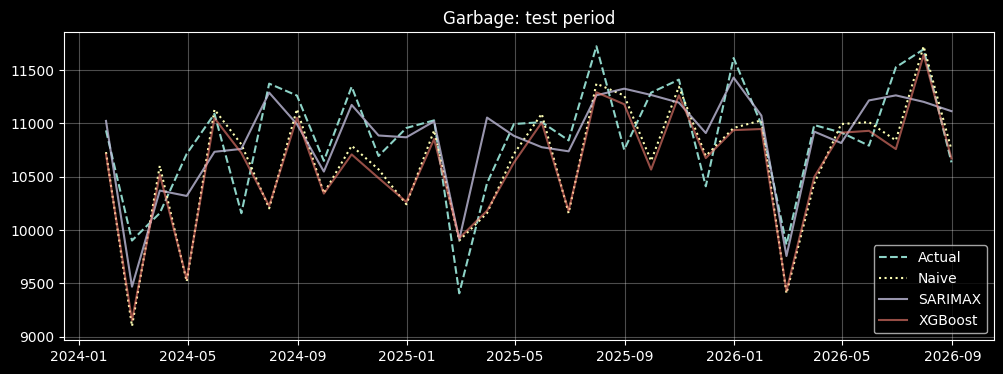

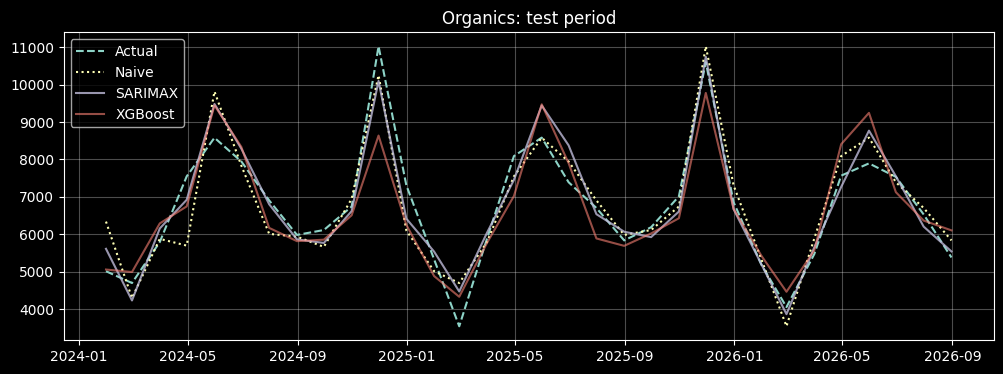

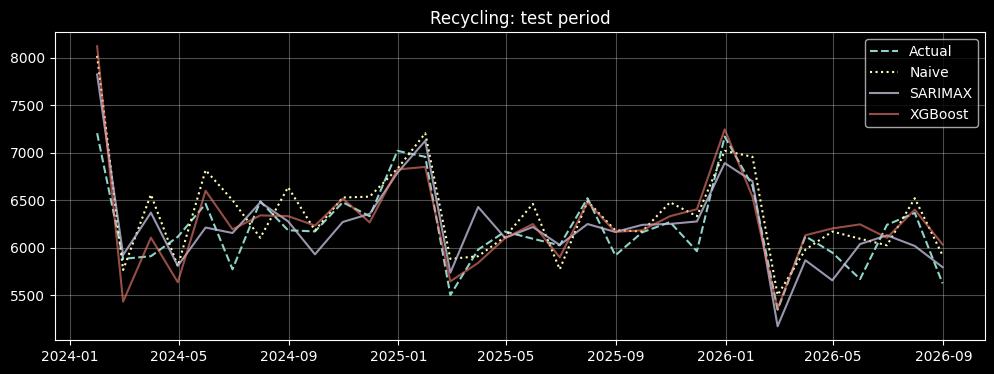

                             MAE    RMSE  MAPE
Stream    Model                               
Garbage   Seasonal Naive  403.57  508.58  3.74
          SARIMAX         266.47  325.05  2.49
          XGBoost         403.54  507.01  3.73
Organics  Seasonal Naive  495.77  661.47  7.86
          SARIMAX         407.13  509.38  6.21
          XGBoost         577.54  742.14  8.23
Recycling Seasonal Naive  268.31  330.49  4.35
          SARIMAX         215.20  260.01  3.48
          XGBoost         201.09  282.76  3.26


In [92]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import mean_absolute_error, mean_squared_error

TEST_START, TEST_END = '2024-01-31', '2026-08-31'

def metrics(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAPE': np.mean(np.abs((y_true - y_pred) / y_true)) * 100,
    }

def run_stream(stream,source_df):
    df = prep(stream, source_df)
    train = df[:TRAIN_END]
    test = df[TEST_START:TEST_END]
    results = {}

    # Scaling for SARIMAX (fit on train only)
    sc = StandardScaler()
    train_s = train.copy()
    test_s = test.copy()
    train_s[exog_cols] = sc.fit_transform(train[exog_cols])
    test_s[exog_cols] = sc.transform(test[exog_cols])

    # 1. Seasonal naive baseline (same month last year)
    naive = df[stream].shift(12)[TEST_START:TEST_END]
    results['Seasonal Naive'] = metrics(test[stream], naive)

    # 2. SARIMAX
    orders = {
    'Garbage':   ((2, 1, 1), (1, 1, 1, 12)),
    'Organics':  ((1, 1, 1), (0, 1, 1, 12)), 
    'Recycling': ((2, 1, 1), (1, 1, 1, 12)),   # filled from AIC search
     
    }
    order, seasonal = orders[stream]
    sar = SARIMAX(train_s[stream], exog=train_s[feats],
              order=order, seasonal_order=seasonal).fit(disp=False)
    sar_ext = sar.extend(test_s[stream], exog=test_s[feats])   # one-step-ahead, use endo data from t-1, exo data from t to predict. Update with actual endo data for new predictions
    sar_pred = sar_ext.predict(start=test.index[0], end=test.index[-1])
    results['SARIMAX'] = metrics(test[stream], sar_pred)

    # 3. XGBoost
    x, xcols = feat_eng(stream,source_df)
    xtr, xte = x[:TRAIN_END], x[TEST_START:TEST_END]
    xgb = XGBRegressor(**params[stream], random_state=42)
    xgb.fit(xtr[xcols], xtr['y_diff'])
    pred_diff = xgb.predict(xte[xcols]) # output predicted changes from same month last year
    xgb_pred = pd.Series(pred_diff + xte['lag_12'], index=xte.index) # add the value last year to the changes so the predicted values on same scale to measure errors
    results['XGBoost'] = metrics(xte[stream], xgb_pred)

    # Comparing actual vs three models' performances
    plt.figure(figsize=(12, 4))
    plt.plot(xte.index, xte[s],'--', label='Actual')
    plt.plot(xte.index, naive,':', label='Naive')
    plt.plot(xte.index, sar_pred, alpha=0.8, label='SARIMAX')
    plt.plot(xte.index, xgb_pred, alpha=0.6, label='XGBoost')
    plt.title(f'{stream}: test period')
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

    return pd.DataFrame(results).T.round(2), sar, xgb, xcols

all_results = {}
for s in ['Garbage','Organics', 'Recycling']:
    all_results[s], *_ = run_stream(s,waste_df)

print(pd.concat(all_results, names=['Stream', 'Model']))

Garbage
- SARIMAX has the lowest MAE and RMSE.
- XGBoost and Seasonal Naive have very similar performance.
- SARIMAX has the lowest average percentage error relative to actual garbage tonnage.
- SARIMAX produces more accurate predictions and has smaller overall errors

Organics
- SARIMAX performs best on both metrics.
- XGBoost has the highest MAE and RMSE, worse than Naive
- XGBoost makes more and larger prediction errors on average.
- Organics appears more difficult to forecast accurately than Garbage and Recycling.

Recycling
- XGBoost has the lowest MAE (201.09).
- SARIMAX has the lowest RMSE (260.01).
- XGBoost has smaller average absolute errors, but appears to have some larger individual prediction errors.

Because tree-based models cannot extrapolate beyond the target values seen in training, XGBoost was trained on the year-over-year change in tonnage and the forecast was reconstructed by adding the predicted change to the value observed 12 months earlier. This removed the systematic bias that the level-based model showed after the post-COVID level shifts, bringing XGBoost to the seasonal naive baseline for Garbage and to a level comparable with SARIMAX for Recycling (lower MAE and MAPE, higher RMSE). For Organics, whose seasonal amplitude varies strongly between years, XGBoost still trailed both the baseline and SARIMAX. Overall, SARIMAX gave the most consistent accuracy across the three streams, which is plausible given the small sample (about 165 monthly observations), its explicit seasonal differencing, and its use of the previous month’s forecast error in one-step-ahead prediction.

Garbage: train range 7723-12131 | test range 9407-11723


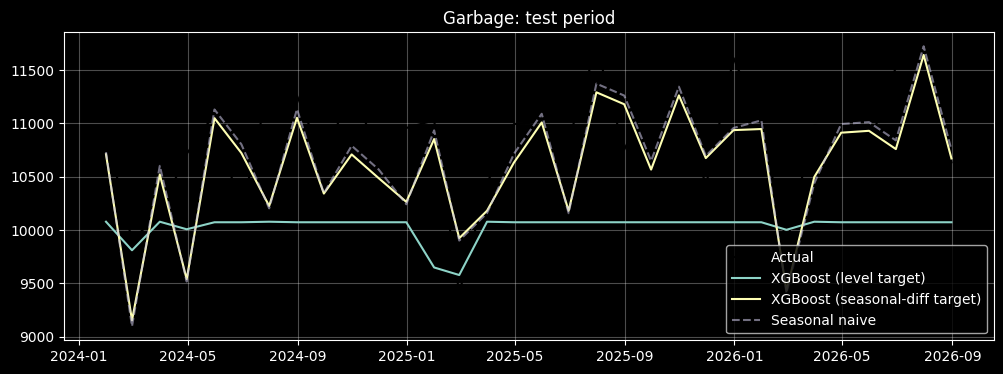

Organics: train range 3154-12443 | test range 3546-11023


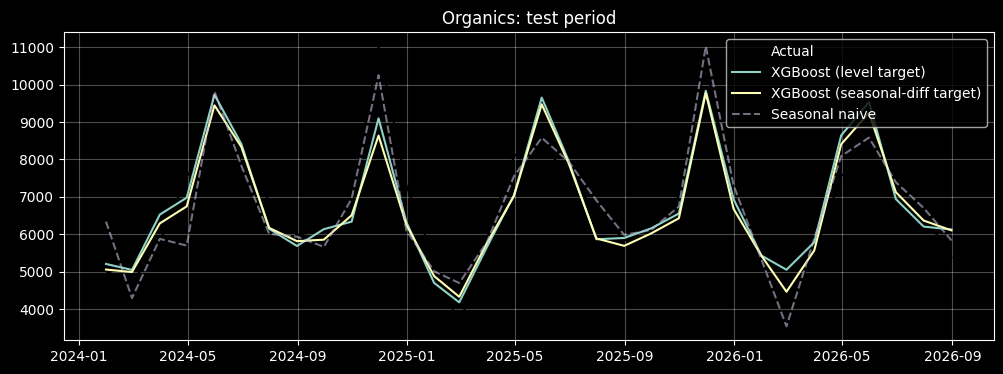

Recycling: train range 5765-9062 | test range 5347-7206


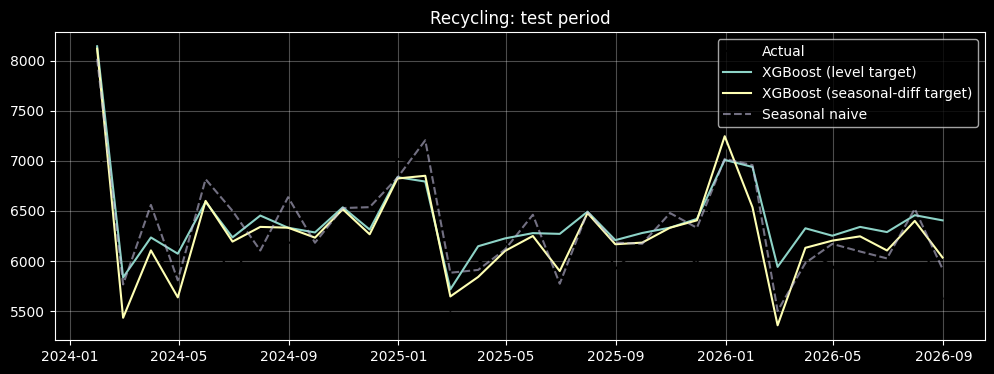

                                 Bias    MAE   RMSE
Stream    Target                                   
Garbage   Level target          828.2  847.6  964.4
          Seasonal-diff target  259.2  403.5  507.0
Organics  Level target          -16.2  631.0  770.0
          Seasonal-diff target   81.6  577.5  742.1
Recycling Level target         -195.9  238.3  329.3
          Seasonal-diff target  -71.5  201.1  282.8


In [93]:
import matplotlib.pyplot as plt

rows = []
for s in streams:
    x, xcols = feat_eng(s, waste_df)
    xtr, xte = x[:TRAIN_END], x[TEST_START:TEST_END]

    # A) Level target (before)
    m_lvl = XGBRegressor(**params[s], random_state=42).fit(xtr[xcols], xtr[s])
    pred_lvl = pd.Series(m_lvl.predict(xte[xcols]), index=xte.index)

    # B) Seasonally differenced target (after): predict change, add lag_12 back
    m_dif = XGBRegressor(**params[s], random_state=42).fit(xtr[xcols], xtr['y_diff'])
    pred_dif = pd.Series(m_dif.predict(xte[xcols]) + xte['lag_12'], index=xte.index)

    for name, pred in [('Level target', pred_lvl), ('Seasonal-diff target', pred_dif)]:
        err = xte[s] - pred
        rows.append({'Stream': s, 'Target': name,
                     'Bias': round(err.mean(), 1),
                     'MAE': round(err.abs().mean(), 1),
                     'RMSE': round(np.sqrt((err**2).mean()), 1)})

    print(f"{s}: train range {xtr[s].min():.0f}-{xtr[s].max():.0f} | "
          f"test range {xte[s].min():.0f}-{xte[s].max():.0f}")

    plt.figure(figsize=(12, 4))
    plt.plot(xte.index, xte[s], label='Actual', color='black')
    plt.plot(xte.index, pred_lvl, label='XGBoost (level target)')
    plt.plot(xte.index, pred_dif, label='XGBoost (seasonal-diff target)')
    plt.plot(xte.index, xte['lag_12'], '--', label='Seasonal naive', alpha=0.6)
    plt.title(f'{s}: test period')
    plt.legend(); plt.grid(alpha=0.3); plt.show()

print(pd.DataFrame(rows).set_index(['Stream', 'Target']))

no visible upward/downward trend, so climatology monthly average is a reasonable input value

### Forecasting steps

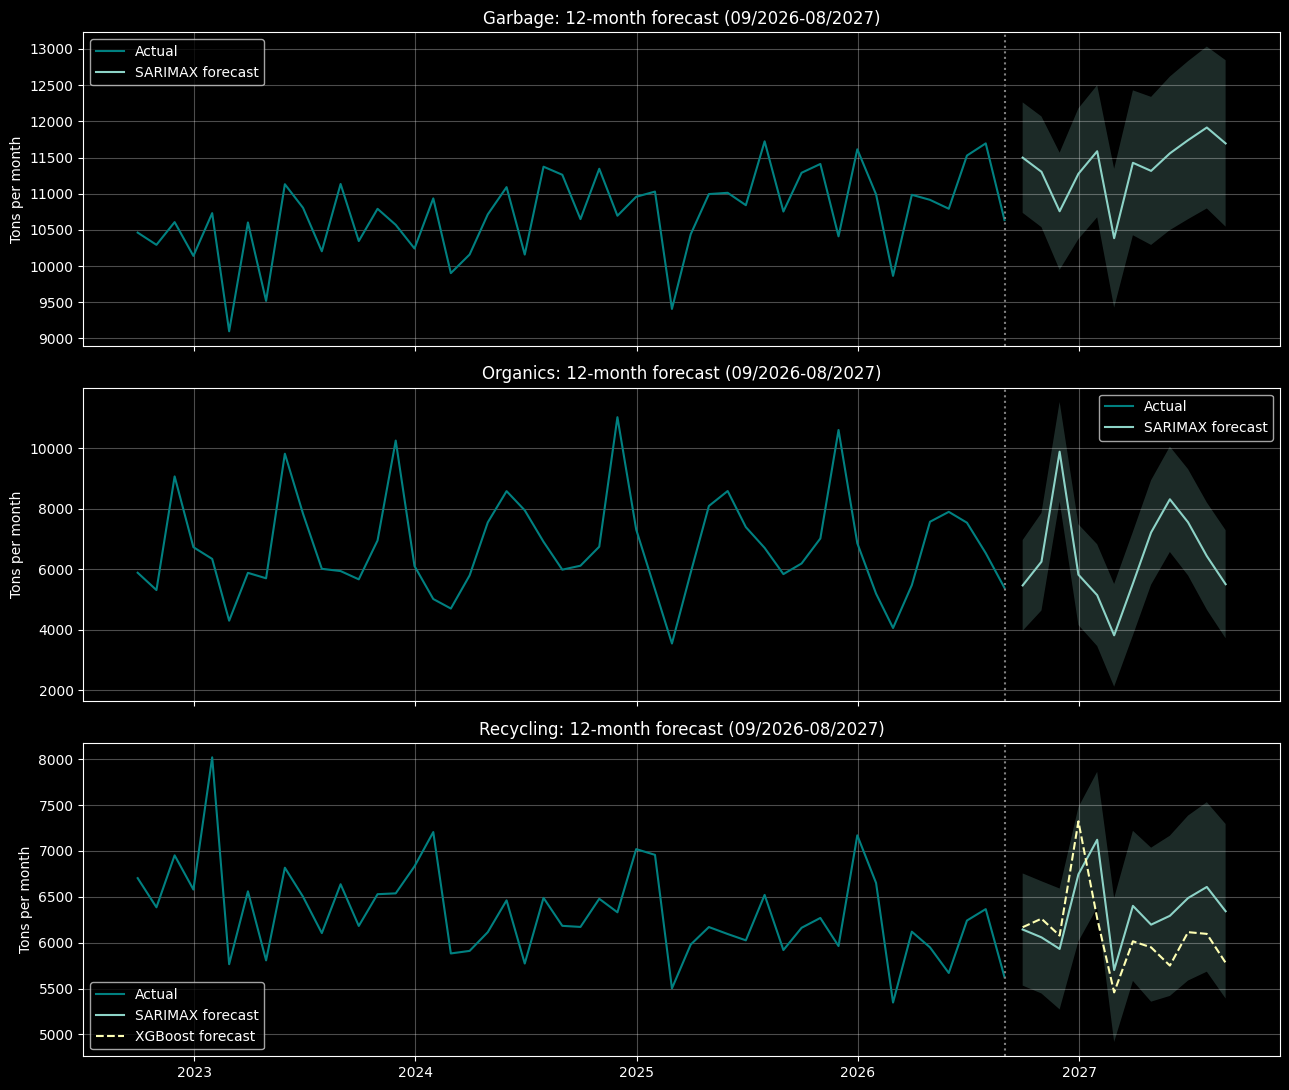

In [94]:
idx_fut = pd.date_range('2026-09-30', '2027-08-31', freq='ME')
orders = {
    'Garbage':   ((2, 1, 1), (1, 1, 1, 12)),
    'Organics':  ((1, 1, 1), (0, 1, 1, 12)), 
    'Recycling': ((2, 1, 1), (1, 1, 1, 12))}

def future_exog(df, idx_fut):
    """Climatological weather, observed/trended households, covid = 0."""
    clim = df.groupby(df.index.month)[['avg_temp', 'tot_rain']].mean()
    hh_obs = df['Households'].groupby(df.index.year).first()
    fit = hh_obs.loc[2022:2026] # more recent observations follow the slope better
    slope, intercept = np.polyfit(fit.index, fit.values, 1)

    fut = pd.DataFrame(index=idx_fut)
    fut['avg_temp'] = clim.loc[idx_fut.month, 'avg_temp'].values
    fut['tot_rain'] = clim.loc[idx_fut.month, 'tot_rain'].values
    fut['Households'] = [hh_obs[y] if y in hh_obs.index else intercept + slope * y
                         for y in idx_fut.year]          # 2026 observed, 2027 extrapolated
    fut['covid'] = 0
    return fut[feats]

def forecast_xgb(model, df, xcols, stream, idx_fut, exog_fut):
    """Recursive multi-step forecast: each prediction feeds the next month's features."""
    hist = df[stream].copy()                 # observed tonnage; predictions get appended
    n, preds = len(df), []
    for i, d in enumerate(idx_fut):
        row = exog_fut.loc[[d]].copy()
        row['lag_1'] = hist.iloc[-1] #In the forecast, hist ends at the month before the one being predicted (call it t-1), so counting back from the end gives the same quantities
        row['lag_12'] = hist.iloc[-12]
        row['roll_3'] = hist.iloc[-3:].mean() 
        row['month'] = d.month
        ychange = model.predict(row[xcols])[0]
        yhat = hist.iloc[-12] + ychange  # add lag_12 back for the change target
        hist.loc[d] = yhat # use the current forecast for the next forecast
        preds.append(yhat)
    return pd.Series(preds, index=idx_fut, name=stream)

def forecast_sarimax(df, stream, order, seasonal, idx_fut, exog_fut):
    """Refit on all data (with scaler), then multi-step forecast."""
    sc = StandardScaler()
    full_s, fut_s = df.copy(), exog_fut.copy()
    full_s[exog_cols] = sc.fit_transform(df[exog_cols])
    fut_s[exog_cols] = sc.transform(exog_fut[exog_cols])
    res = SARIMAX(full_s[stream], exog=full_s[feats],
                  order=order, seasonal_order=seasonal).fit(disp=False)
    sar_fc = res.get_forecast(steps=len(idx_fut), exog=fut_s[feats])
    pred, ci = sar_fc.predicted_mean, sar_fc.conf_int()
    return pred, ci # for plotting

forecasts, sarimax_ci = {}, {}

# 1. SARIMAX for all three streams
for s in streams:
    df = prep(s, waste_df)                          # all data through 2026-08
    exog_fut = future_exog(df, idx_fut)
    order, seasonal = orders[s]
    forecasts[(s, 'SARIMAX')], sarimax_ci[s] = forecast_sarimax(df, s, order, seasonal, idx_fut, exog_fut)

# 2. XGBoost for Recycling: refit on all rows, then recurse
s = 'Recycling'
df = prep(s, waste_df)
exog_fut = future_exog(df, idx_fut)
x, xcols = feat_eng(s, waste_df)
model = XGBRegressor(**params[s], random_state=42).fit(x[xcols], x['y_diff'])
forecasts[(s, 'XGBoost')] = forecast_xgb(model, df, xcols, s, idx_fut, exog_fut)

# 3. Plot: last 4 years of actuals + forecasts
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
for ax, s in zip(axes, ['Garbage', 'Organics', 'Recycling']):
    hist = prep(s, waste_df)[s].loc['2022-09':]
    ax.plot(hist.index, hist, color='teal', label='Actual')

    f = forecasts[(s, 'SARIMAX')]
    ax.plot(f.index, f, label='SARIMAX forecast')
    ci = sarimax_ci[s]
    ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2)

    if (s, 'XGBoost') in forecasts: # bypass skipping xgboost for garbage and organics
        ax.plot(idx_fut, forecasts[(s, 'XGBoost')], '--', label='XGBoost forecast')

    ax.axvline(pd.Timestamp('2026-08-31'), color='gray', ls=':')   # forecast start
    ax.set_title(f'{s}: 12-month forecast (09/2026-08/2027)')
    ax.set_ylabel('Tons per month')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [95]:
forecasts.keys()

dict_keys([('Garbage', 'SARIMAX'), ('Organics', 'SARIMAX'), ('Recycling', 'SARIMAX'), ('Recycling', 'XGBoost')])

In [96]:
# 1. Every model forecast, side by side (includes both Recycling models for comparison)
all_fc = pd.DataFrame(forecasts)
all_fc.columns = [f'{stream} ({model})' for stream, model in all_fc.columns]
all_fc.index.name = 'Date'
# Choose XGBoost for Recycling
all_fc = all_fc.drop(columns='Recycling (SARIMAX)')
all_fc['total_msw'] = all_fc.sum(axis=1)
all_fc['diversion_rate'] = (all_fc['Recycling (XGBoost)'] + all_fc['Organics (SARIMAX)']) / all_fc['total_msw']
all_fc

,Garbage (SARIMAX),Organics (SARIMAX),Recycling (XGBoost),total_msw,diversion_rate
Date,,,,,
2026-09-30,11498.294075,5465.046341,6168.675754,23132.016170,0.502927
2026-10-31,11302.637344,6247.577211,6261.683363,23811.897918,0.525337
2026-11-30,10757.047880,9882.077424,6077.257445,26716.382749,0.597361
2026-12-31,11274.997790,5820.143248,7323.011211,24418.152249,0.538253
2027-01-31,11586.678127,5143.092462,6265.793267,22995.563856,0.496134
2027-02-28,10384.833499,3816.480798,5457.981735,19659.296033,0.471760
2027-03-31,11426.841596,5526.593481,6015.142529,22968.577605,0.502501
2027-04-30,11314.994174,7214.766018,5949.011317,24478.771508,0.537763
2027-05-31,11557.367171,8310.719815,5750.083164,25618.170150,0.548861


#### Scenario Analysis
##### Ties to Seattle's current lack of Food Waste Target. 
- Seattle residents and businesses threw away about 53,700 tons of food waste in the garbage in 2025, roughly 20% of disposed tons (SPU, 2026 [use the report’s exact title and year]). No numeric food waste target was identified in SPU’s published metrics, so the scenarios are hypothetical. Assuming food waste stays at 20% of the forecast Garbage stream, the scenarios capture 20%, 30%, and 50% of that food waste in the Organics stream over the forecast window (09/2026 to 08/2027), keeping total MSW constant. For each scenario, the diversion rate is recalculated as (Organics + Recycling) / total MSW.
- For Recycling, the report explains the residential recycling capture rate differently. It is the total tons of recyclable materials in the recycling stream divided by the total tons of
recyclables across the garbage, recycling, and organics stream

The analysis below aims to combine food rate reduction and recycling targets


In [97]:
fc = all_fc[['Garbage (SARIMAX)', 'Organics (SARIMAX)', 'Recycling (XGBoost)']].copy()
fc.columns = ['Garbage', 'Organics', 'Recycling']
tot = fc.sum()                                  # tons over the 12-month window (09/2026-08/2027)
total_msw = tot.sum()  
# Foodwaste 
foodwaste = 0.2 * tot['Garbage']
target_capture = (0.2, 0.3, 0.5) # reduce landfill foodwaste by 20%, 30%, 50% (hypothethical)

# Recycling
current_rate = 0.74      # SPU residential recycling capture rate, 2024 report (update with the latest)
target_rate = 0.79 # hypothetical

# Recyclable material in all residential waste, implied by the current capture rate
rec_potential   = tot['Recycling'] / current_rate # recycling stream and recycles in all streams
rec_in_garbage = rec_potential - tot['Recycling']
rec_capture = (target_rate - current_rate) * rec_potential   # extra tons captured
rec_capture = min(rec_capture, rec_in_garbage)

rows = []
for t in target_capture:
    fw_diverted = foodwaste * t
    target_garbage = tot['Garbage'] - fw_diverted - rec_capture
    target_organics = tot['Organics'] + fw_diverted
    target_recycling = tot['Recycling'] + rec_capture
    rows.append({
        'Capture of foodwaste' : t,
        'Capture of Recycling': target_rate,
        'Tons Food Captured' : round(fw_diverted),
        'Tons Recycling Captured': round(rec_capture),
        'Garbage (tons)' : round(target_garbage),
        'Organics (tons)' : round(target_organics),
        'Recylcing (tons)' : round(tot['Recycling']),
        'Diversion rate' : round((target_organics + tot['Recycling'])/total_msw,2)
    })
analysis = pd.DataFrame(rows)
print(analysis)

   Capture of foodwaste  Capture of Recycling  Tons Food Captured  \
0                   0.2                  0.79                5458   
1                   0.3                  0.79                8187   
2                   0.5                  0.79               13645   

   Tons Recycling Captured  Garbage (tons)  Organics (tons)  Recylcing (tons)  \
0                     4950          126044            82374             73260   
1                     4950          123315            85103             73260   
2                     4950          117857            90561             73260   

   Diversion rate  
0            0.54  
1            0.55  
2            0.57  


#### Feature Importance Analysis

In [98]:
# XGBoost feature importance
for s in streams:
    x, xcols = feat_eng(s, waste_df)
    xtr= x[:TRAIN_END]
    model = XGBRegressor(**params[s], random_state=42)
    model.fit(xtr[xcols], xtr['y_diff'])
    importances_xg = pd.DataFrame({
        'feature': xcols,
        'importance': model.feature_importances_,
    }).sort_values(by='importance', ascending=False)
    print(f'Feature Importance on {s} Stream ')
    print(importances_xg)
    print('----------------------------------')

Feature Importance on Garbage Stream 
      feature  importance
3       covid    0.280097
5      lag_12    0.159980
2  Households    0.154665
1    tot_rain    0.140750
0    avg_temp    0.135799
6      roll_3    0.105457
7       month    0.023252
4       lag_1    0.000000
----------------------------------
Feature Importance on Organics Stream 
      feature  importance
5      lag_12    0.158583
0    avg_temp    0.132308
3       covid    0.127757
2  Households    0.127678
4       lag_1    0.116705
6      roll_3    0.116655
1    tot_rain    0.114700
7       month    0.105615
----------------------------------
Feature Importance on Recycling Stream 
      feature  importance
3       covid    0.291566
5      lag_12    0.172815
2  Households    0.148666
1    tot_rain    0.114649
6      roll_3    0.078027
4       lag_1    0.066741
0    avg_temp    0.065069
7       month    0.062467
----------------------------------


The plot shows SARIMAX coefficients of the scaled exogenous variables for each stream. Households had the largest coefficient in all three streams, followed by average temperature and then total rainfall. All coefficients were positive, and Organics had the largest coefficient for each variable (temperature: 760.81; rainfall: 110.06; households: 2,923.78).